# Federal Register 2024-2026: a change of government in the regulatory record

Every document the US Federal Register published from January 2024 to October 2026: 76,223 rules, proposed rules, notices and presidential documents. That spans the last year of the Biden administration and the first 21 months of the second Trump administration.

1. **Volume:** what the regulatory freeze and the 2025 shutdown look like in the data
2. **Administrations:** final rules, executive orders and pages, per month
3. **Agencies:** who publishes more and who publishes less
4. **Comment periods:** how long the public gets to respond
5. **Baseline model:** predicting whether a rule is *significant* (EO 12866) from its text

Every number below is computed in the cell that prints it.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

sns.set_theme(style='whitegrid')


def find_csv(name='federal_register_documents.csv'):
    # Kaggle mounts inputs at a depth that has changed over time; walk for it.
    for root, _, files in os.walk('/kaggle/input'):
        if name in files:
            return Path(root) / name
    return Path(name)


df = pd.read_csv(find_csv(), parse_dates=['publication_date'], low_memory=False)
df['month'] = df.publication_date.dt.to_period('M')
print(f'{len(df):,} documents, {df.publication_date.min():%Y-%m-%d} to {df.publication_date.max():%Y-%m-%d}')
df.type.value_counts()

76,223 documents, 2024-01-02 to 2026-10-30


type
Notice                   62291
Rule                      8161
Proposed Rule             4765
Presidential Document     1006
Name: count, dtype: int64

## 1. Volume: the freeze and the shutdown

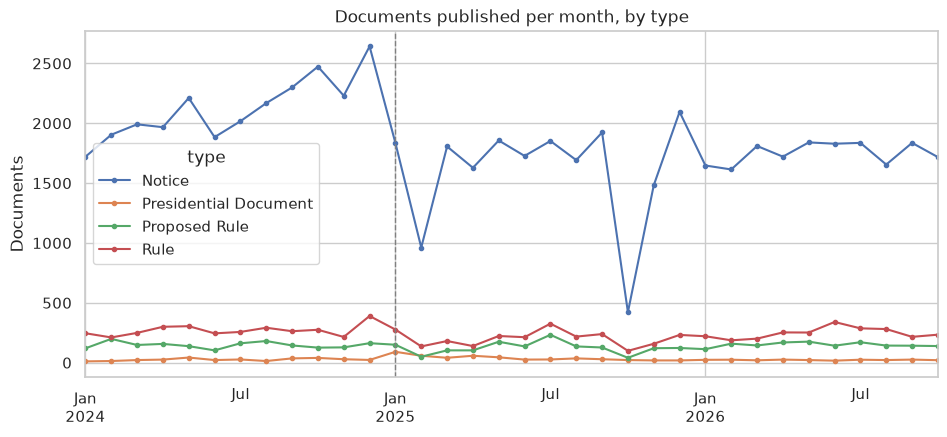

Median month: 2,308 documents
2025-02: 1,206 documents (-48%)
2025-10: 584 documents (-75%)


In [2]:
monthly = df.pivot_table(index='month', columns='type', values='document_number',
                         aggfunc='count', fill_value=0)
ax = monthly.plot(figsize=(11, 4.5), marker='.')
ax.axvline(pd.Period('2025-01', 'M'), color='grey', ls='--', lw=1)
ax.set(title='Documents published per month, by type', xlabel='', ylabel='Documents')
plt.show()

total = monthly.sum(axis=1)
typical = total.drop([pd.Period('2025-02', 'M'), pd.Period('2025-10', 'M')]).median()
print(f'Median month: {typical:,.0f} documents')
for m in ['2025-02', '2025-10']:
    print(f'{m}: {total[pd.Period(m, "M")]:,} documents ({total[pd.Period(m, "M")] / typical - 1:+.0%})')

Two dips stand out. **February 2025** follows the 20 January regulatory freeze memo, which withdrew rules not yet published and paused new ones. **October 2025** is the government shutdown (1 October to 12 November 2025); agencies with lapsed funding stopped sending documents.

## 2. Administrations: rules, executive orders and pages per month

In [3]:
df['admin'] = np.where(df.publication_date < '2025-01-20', 'Biden (Jan 2024 - Jan 2025)',
                       'Trump (Jan 2025 - Oct 2026)')
# Months in office within the window (the Biden span ends on 19 January 2025).
months = pd.Series({'Biden (Jan 2024 - Jan 2025)': (pd.Timestamp('2025-01-20') - pd.Timestamp('2024-01-01')).days,
                    'Trump (Jan 2025 - Oct 2026)': (pd.Timestamp('2026-11-01') - pd.Timestamp('2025-01-20')).days}) / 30.44
per_month = pd.DataFrame({
    'final rules': df[df.type == 'Rule'].groupby('admin').size(),
    'proposed rules': df[df.type == 'Proposed Rule'].groupby('admin').size(),
    'executive orders': df[df.subtype == 'Executive Order'].groupby('admin').size(),
    'significant final rules': df[(df.type == 'Rule') & (df.significant == True)].groupby('admin').size(),
    'Federal Register pages': df.groupby('admin').page_length.sum(),
}).div(months, axis=0)
per_month.round(1)

,final rules,proposed rules,executive orders,significant final rules,Federal Register pages
admin,,,,,
Biden (Jan 2024 - Jan 2025),274.8,148.5,2.4,30.0,11169.8
Trump (Jan 2025 - Oct 2026),219.4,135.2,13.8,15.6,7506.9


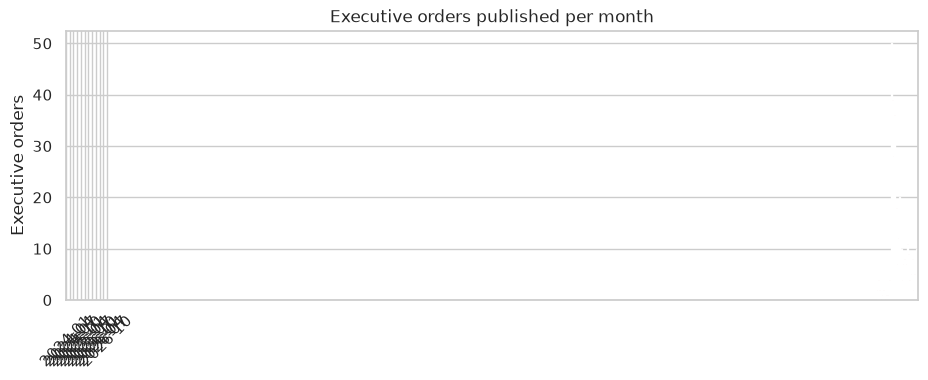

325 executive orders in the window; numbers 14115 to 14438.


In [4]:
eo = df[df.subtype == 'Executive Order']
eo_monthly = eo.groupby('month').size().reindex(monthly.index, fill_value=0)
ax = eo_monthly.plot.bar(figsize=(11, 3.5), color='tab:red', width=0.8)
ax.set_xticks(range(0, len(eo_monthly), 3), [str(m) for m in eo_monthly.index[::3]], rotation=45)
ax.set(title='Executive orders published per month', xlabel='', ylabel='Executive orders')
plt.show()
print(f'{len(eo):,} executive orders in the window; numbers {int(eo.executive_order_number.min())} '
      f'to {int(eo.executive_order_number.max())}.')

In [5]:
final = df[df.type == 'Rule'].copy()
final['deregulatory_title'] = final.title.str.contains(
    r'\b(?:rescission|rescind|rescinding|repeal|repealing|removal|removing|withdrawal|delay of)\b', case=False)
print('Share of final rules whose title announces a rescission, repeal, removal, withdrawal or delay:')
print(final.groupby('admin').deregulatory_title.mean().map('{:.1%}'.format).to_string())

Share of final rules whose title announces a rescission, repeal, removal, withdrawal or delay:
admin
Biden (Jan 2024 - Jan 2025)    1.8%
Trump (Jan 2025 - Oct 2026)    6.7%


A crude keyword count, not a legal classification. Some removals are technical clean-ups, and some deregulatory rules have neutral titles. It still shows the direction of the change.

## 3. Agencies: who publishes more and who publishes less

In [6]:
rules = df[df.type.isin(['Rule', 'Proposed Rule'])]
by_agency = (rules.groupby(['agency', 'admin']).size().unstack(fill_value=0)
             .div(months, axis=1))
by_agency.columns = ['Biden / month', 'Trump / month']
by_agency = by_agency[by_agency.sum(axis=1) >= 5]
by_agency['change'] = by_agency['Trump / month'] / by_agency['Biden / month'] - 1
by_agency.sort_values('Biden / month', ascending=False).head(15).style.format(
    {'Biden / month': '{:.1f}', 'Trump / month': '{:.1f}', 'change': '{:+.0%}'})

,Biden / month,Trump / month,change
agency,,,
Transportation Department,95.6,103.9,+9%
Environmental Protection Agency,54.8,44.0,-20%
Homeland Security Department,43.0,36.4,-15%
Commerce Department,37.7,27.5,-27%
Treasury Department,23.2,13.9,-40%
Health and Human Services Department,19.3,18.0,-7%
Federal Communications Commission,17.4,13.0,-25%
Interior Department,16.2,12.3,-24%
Agriculture Department,14.5,10.6,-27%


Rules and proposed rules per month in office, for agencies with at least five a month across both columns. Routine items such as Coast Guard safety zones and FAA airworthiness directives make up much of the volume, so a change in an agency's count reflects routine output as well as policy.

## 4. Comment periods

                              count   25%   50%   75%
admin                                                
Biden (Jan 2024 - Jan 2025)  1646.0  31.0  45.0  60.0
Trump (Jan 2025 - Oct 2026)  2585.0  31.0  45.0  60.0

Share of proposed rules with a comment period under 30 days:
admin
Biden (Jan 2024 - Jan 2025)    6%
Trump (Jan 2025 - Oct 2026)    5%


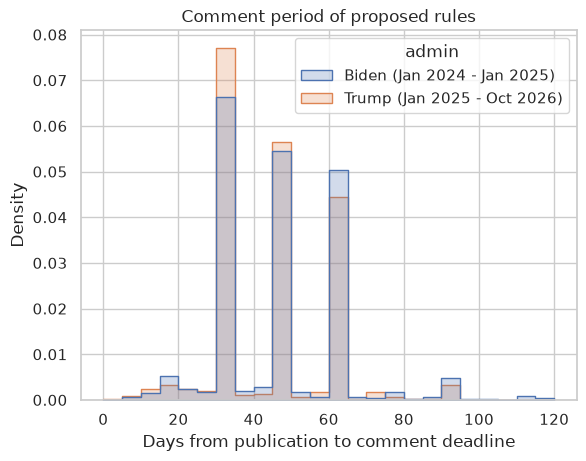

In [7]:
pr = df[(df.type == 'Proposed Rule') & df.comment_period_days.between(1, 365)]
print(pr.groupby('admin').comment_period_days.describe()[['count', '25%', '50%', '75%']])
print()
print('Share of proposed rules with a comment period under 30 days:')
print(pr.groupby('admin').comment_period_days.apply(lambda s: (s < 30).mean()).map('{:.0%}'.format).to_string())
ax = sns.histplot(data=pr, x='comment_period_days', hue='admin', bins=np.arange(0, 125, 5),
                  stat='density', common_norm=False, element='step')
ax.set(title='Comment period of proposed rules', xlabel='Days from publication to comment deadline')
plt.show()

## 5. Baseline: is this rule significant?

OIRA marks a rule *significant* under Executive Order 12866 when it is likely to have an annual effect of $100M or more, or raises novel legal or policy issues. Significant rules get White House review. The label is reported for about half of the rules and proposed rules. That gives a clean, imbalanced text-classification target.

Train on documents published before 2026, test on 2026, so the score reflects predicting rules the model has not seen yet. The features are title, abstract and action line as TF-IDF, plus a one-hot encoding of the agency and the document type.

In [8]:
labelled = rules[rules.significant.notna()].copy()
labelled['y'] = labelled.significant.astype(bool).astype(int)
labelled['text'] = (labelled.title.fillna('') + ' ' + labelled.abstract.fillna('') + ' '
                    + labelled.action.fillna(''))
train = labelled[labelled.publication_date < '2026-01-01']
test = labelled[labelled.publication_date >= '2026-01-01']
print(f'train {len(train):,} ({train.y.mean():.1%} significant), test {len(test):,} ({test.y.mean():.1%} significant)')

model = make_pipeline(
    ColumnTransformer([
        ('text', TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50_000,
                                 sublinear_tf=True, stop_words='english'), 'text'),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=5), ['agency', 'type']),
    ]),
    LogisticRegression(C=4.0, max_iter=2000, class_weight='balanced'),
)
cols = ['text', 'agency', 'type']
model.fit(train[cols], train.y)
p = model.predict_proba(test[cols])[:, 1]
print(f'ROC-AUC {roc_auc_score(test.y, p):.3f}   '
      f'PR-AUC {average_precision_score(test.y, p):.3f} (base rate {test.y.mean():.3f})')

train 5,107 (18.1% significant), test 1,825 (17.5% significant)


ROC-AUC 0.961   PR-AUC 0.821 (base rate 0.175)


In [9]:
vec = model[0].named_transformers_['text']
coef = model[-1].coef_[0][:len(vec.vocabulary_)]
terms = np.array(vec.get_feature_names_out())
order = np.argsort(coef)
print('Most "significant" terms:   ', ', '.join(terms[order[-15:]][::-1]))
print('Most "not significant" terms:', ', '.join(terms[order[:15]]))

Most "significant" terms:    security, impact, agencies, 2026, department, process, vehicle, poultry, advance notice, transportation department, digital, seeking, advance, doe proposing, employees
Most "not significant" terms: direct, area, direct final, tax, obsolete, ad, privacy act, fishery, agreement, privacy, listing, applicable, action, species status, board


## Using this dataset

- One row per document; `document_number` is the key, and `https://www.federalregister.gov/d/<document_number>` opens it.
- `significant` is only reported for rules and proposed rules, and not for all of them; blank means unknown, not false.
- `agency` is the top-level department; `agencies` lists every agency named, sub-agencies included.
- `page_views` is a snapshot count, so older documents have had longer to accumulate views. Normalise by age before comparing.
- `abstract` is blank for most presidential documents. For full text, fetch `https://www.federalregister.gov/documents/full_text/text/...` from the API.

Ideas: classify the agency or document type from the abstract, topic-model executive orders, forecast monthly volume, or model which proposed rules become final.